
# Sample Balance Analysis

**Objective**  
Assess the comparability of respondents assigned to Flow A (no button) and Flow B (with button) before comparing discount noticeability.
The analysis examines sample sizes, prototype completion, and respondent characteristics that may be relevant when interpreting differences between variants.


**Agenda**
1. Setup and Data Ingestion
2. Sample Size by Flow
3. Prototype Completion
4. Gender
5. Age
6. Category Usage
7. Discount Motivated Users
8. Summary

###  1. Setup and Data Ingestion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
from scipy import stats
import pingouin as pg

In [2]:
# display settings for high-dimensional dataset
pd.set_option ('display.max_columns', 50)
pd.set_option ('display.max_rows', 50)

In [3]:
# Load the dataset. Low_memory = False handles mixed types across columns
DATA_PATH = '../data/P1_FTD_cleaned_sample.csv'
df = pd.read_csv(DATA_PATH, low_memory = False)
print(f"Cleaned dataset loaded: {df.shape[0]} sessions, {df.shape[1]} columns")

Cleaned dataset loaded: 198 sessions, 175 columns


### 2. Sample Size by Flow
Check whether the number of sessions is comparable across flows

In [4]:
# inspect session distribution by prototype flow
counts_by_flow = df['Flow'].value_counts()
share_by_flow = df['Flow'].value_counts(normalize=True).mul(100).round(2)

flow_summary = pd.DataFrame ({'sessions': counts_by_flow,
                              'sample_share': share_by_flow})

print(f"Session count by flow:\n{flow_summary}")

Session count by flow:
                      sessions  sample_share
Flow                                        
Flow A (no button)         100         50.51
Flow B (with button)        98         49.49


The cleaned sample contains 100 respondents in Flow A (50.51%) and 98 in Flow B (49.49%).   
The retained sample sizes are nearly equal.

### 3. Prototype Completion
Compare the share of respondents who self-reportedly completed the prototype from start to finish across flows.

Differences in self-reported completion may indicate differences in usability or technical difficulties between prototypes.

To verify completion, I examine the progression across attempts:
- Q9: First attempt completion status.
- Q10: Prompt to retry the prototype if the first attempt failed.
- Q11: Second attempt completion status.

In [5]:
#define the target questions
Q9_1ST_ATTEMPT = [c for c in df.columns if c.startswith ('Q9.')][0]
Q11_2ND_ATTEMPT = [c for c in df.columns if c.startswith ('Q11.')][0]

#inspect the values within the columns and checking the overall number of sessions with incomplete flows 
q9_1st_attempt_counts = df[Q9_1ST_ATTEMPT].value_counts(dropna=False)
q11_2nd_attempt_counts = df[Q11_2ND_ATTEMPT].value_counts(dropna=False)

print(f"1st attempt:\n{q9_1st_attempt_counts.to_string()}")
print(f"\n2nd attempt:\n{q11_2nd_attempt_counts.to_string()}")

1st attempt:
Q9. Were you able to go through the deposit process from start to finish? Answer
Yes, I saw the final screen with the "Payment completed" notification.    147
No                                                                         51

2nd attempt:
Q11. Were you able to go through the deposit process from start to finish? Answer
NaN                                                                       147
Yes, I saw the final screen with the "Payment completed" notification.     27
No                                                                         24


On the first attempt (Q9), 51 out of 198 respondents reported being unable to finish the deposit flow.
After the retry prompt (Q10–Q11), 27 of them reported reaching the final confirmation screen, leaving 24 respondents who reported not completing the prototype.

In [6]:
# a respondent finished the flow if they completed on 1st attempt (Q9) or in the 2nd attempt (Q11)
completed_q9  = df[Q9_1ST_ATTEMPT].str.startswith('Yes', na = False)
completed_q11 = df[Q11_2ND_ATTEMPT].str.startswith('Yes', na = False)

# flag respondents reporting prototype completion
df['flow_is_completed'] = completed_q9 | completed_q11

# calculate the overall completion distribution
completion_pct = (df['flow_is_completed']
                  .value_counts(normalize = True)
                  .mul(100)
                  .round(2))

print(f"Overall prototype completion (%):\n{completion_pct.to_string()}")

Overall prototype completion (%):
flow_is_completed
True     87.88
False    12.12


Overall, 24 out of 198 respondents (12.1%) reported not going through the end of the prototype. Next, I compare incompletion rates across flows to identify any observed difference between variants.

In [7]:
# build crosstable to inspect completion distribution across prototype flows

completion_counts_by_flow = (pd.crosstab (df['flow_is_completed'], df['Flow'])
                            .rename(index = {False: 'Incomplete', True: 'Complete'}))


completion_pct_by_flow = (pd.crosstab (df['flow_is_completed'], df['Flow'], normalize = 'columns')
                      .mul(100)
                      .round(2)
                      .rename(index = {False: 'Incomplete (%)', True: 'Complete (%)'})
                      .reset_index()
                      )
completion_pct_by_flow['delta_pp'] = completion_pct_by_flow['Flow A (no button)'] - completion_pct_by_flow['Flow B (with button)']

print('Prototype completion by flow (counts)')
display(completion_counts_by_flow)
print('\nPrototype completion by flow (%)')
display(completion_pct_by_flow)

Prototype completion by flow (counts)


Flow,Flow A (no button),Flow B (with button)
flow_is_completed,,
Incomplete,12,12
Complete,88,86



Prototype completion by flow (%)


Flow,flow_is_completed,Flow A (no button),Flow B (with button),delta_pp
0,Incomplete (%),12.0,12.24,-0.24
1,Complete (%),88.0,87.76,0.24


The prototype self-reported incompletion is virtually identical across variants: **12.00%** for Flow A (no button) and **12.24%** for Flow B (with button). 

Since the drop-off is symmetrically distributed, it does not represent an observed sample imbalance.

**Methodological Note on Retaining Incomplete Sessions:**  
Respondents with incomplete prototype flows passed the initial data quality and eligibility checks. Prototype incompletion alone is therefore not treated as grounds for exclusion.

Excluding these respondents could introduce survivorship bias and mask usability difficulties experienced by those who did not complete the flow. Therefore, all 198 respondents are retained for subsequent analysis.

### 4. Gender
Compare gender composition across Flow A and Flow B.

In [8]:
# define target question and inspect values, including missing responses
Q3_GENDER_COL = [c for c in df.columns if c.startswith('Q3.')][0]
gender_counts = df[Q3_GENDER_COL].value_counts(dropna=False)

print(f"Overall gender breakdown:\n{gender_counts.to_string()}")

Overall gender breakdown:
Q3. What is your gender? Answer
Male      137
Female     61


In [9]:
# count respondents by gender within each flow
gender_counts_by_flow = pd.crosstab(
    df[Q3_GENDER_COL],
    df['Flow']
)

# calculate gender proportions within each flow
gender_pct_by_flow = (
    gender_counts_by_flow
    .div(gender_counts_by_flow.sum(axis=0), axis='columns')
    .mul(100)
    .round(2)
)
gender_pct_by_flow['delta_pp'] = gender_pct_by_flow['Flow A (no button)'] - gender_pct_by_flow['Flow B (with button)']


print("Gender distribution by flow (counts)")
display (gender_counts_by_flow)
print("Gender distribution by flow (%)")
display (gender_pct_by_flow)

Gender distribution by flow (counts)


Flow,Flow A (no button),Flow B (with button)
Q3. What is your gender? Answer,,
Female,26,35
Male,74,63


Gender distribution by flow (%)


Flow,Flow A (no button),Flow B (with button),delta_pp
Q3. What is your gender? Answer,,,
Female,26.0,35.71,-9.71
Male,74.0,64.29,9.71


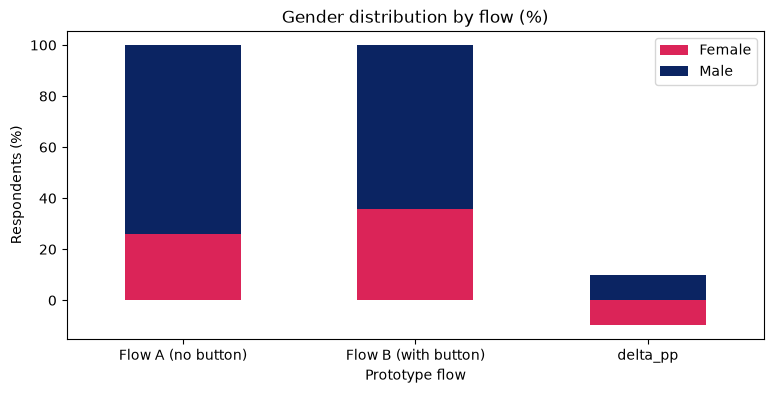

In [10]:
#visualise the comparison
gender_ax = gender_pct_by_flow.T.plot (kind = 'bar', stacked = True, figsize = (9,4),color=["#DB2458", "#0B2462"])

gender_ax.set_title('Gender distribution by flow (%)')
gender_ax.set_xlabel('Prototype flow')
gender_ax.tick_params(axis='x', labelrotation=0)
gender_ax.set_ylabel('Respondents (%)')
gender_ax.legend (loc = 'upper right')

plt.show ()

Gender proportions differ between Flow A and Flow B. I will use a Pearson chi-square test to check whether this difference is statistically significant (α = 0.05).

- H0: Gender and flow assignment are independent: the underlying gender distribution is the same across flows.
- H1: Gender and flow assignment are associated: the underlying gender distribution differs across flows.

In [11]:
# run the chi-square test
gender_expected, _, gender_stats = pg.chi2_independence(data=df, x=Q3_GENDER_COL, y='Flow')

gender_chi2_results = gender_stats.loc[gender_stats['test'].eq('pearson')].round(2)

# Print the results
print("Expected frequencies under H0")
display(gender_expected.round(2))
print("\nResults")
display(gender_chi2_results)

Expected frequencies under H0


Flow,Flow A (no button),Flow B (with button)
Q3. What is your gender? Answer,,
Female,30.81,30.19
Male,69.19,67.81



Results


,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.0,1.76,1.0,0.18,0.09,0.26


Most respondents are male in both flows: 74.00% in Flow A and 64.29% in Flow B, a difference of 9.71 percentage points.

**This difference is not statistically significant (p = 0.18), so H0 is not rejected at α = 0.05. Cramer’s V = 0.09 suggests a weak link between gender and flow assignment.**

However, the difference in gender composition could still matter if men and women differ in how often they notice discounts.

### 5. Age

Compare age composition across Flow A and Flow B using the `age` column created during data cleaning.

In [12]:
#create age groups
age_bins = [17, 34, 54, 65]
age_labels = ['18-34', '35-54', '55-65']
df['age_group'] = pd.cut (df['age'], bins = age_bins, right = True, labels = age_labels)

#double-check the result: inspect min and max age within each group
age_group_bounds = (df.groupby(df['age_group'], as_index = False )
                    .age.agg(min_age = 'min', max_age = 'max'))

print (age_group_bounds)

  age_group  min_age  max_age
0     18-34       18       34
1     35-54       35       54
2     55-65       55       65


In [13]:
# count respondents by age within each flow
age_counts_by_flow = pd.crosstab(df['age_group'], df['Flow'])


# сalculate age group percentages within each flow
age_pct_by_flow = (age_counts_by_flow.div (age_counts_by_flow.sum(axis=0), axis = "columns")
                  .mul(100)
                  .round(2)
)

age_pct_by_flow['delta_pp'] = age_pct_by_flow['Flow A (no button)'] - age_pct_by_flow['Flow B (with button)']

print("Age distribution by flow (counts)")
display (age_counts_by_flow)
print("\nAge distribution by flow (%)")
display (age_pct_by_flow)

Age distribution by flow (counts)


Flow,Flow A (no button),Flow B (with button)
age_group,,
18-34,44,51
35-54,40,39
55-65,16,8



Age distribution by flow (%)


Flow,Flow A (no button),Flow B (with button),delta_pp
age_group,,,
18-34,44.0,52.04,-8.04
35-54,40.0,39.80,0.20
55-65,16.0,8.16,7.84


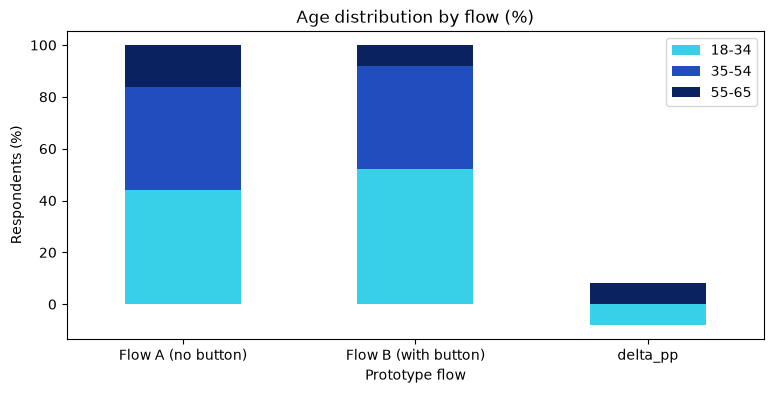

In [14]:
#visualise the comparison
age_ax = age_pct_by_flow.T.plot (kind = 'bar', stacked = True,  figsize = (9,4),color=["#37D0E8", "#214EBF", "#0A225F"])

age_ax.set_title('Age distribution by flow (%)')
age_ax.set_xlabel('Prototype flow')
age_ax.tick_params(axis='x', labelrotation=0)
age_ax.set_ylabel('Respondents (%)')
age_ax.legend (loc = 'upper right')

plt.show ()

Age group proportions differ between Flow A and Flow B. I will use a Pearson chi-square test to check whether this difference is statistically significant (α = 0.05).

- H0: Age group and flow assignment are independent: the underlying age group distribution is the same across flows.
- H1: Age group and flow assignment are associated: the underlying age group distribution differs across flows.

In [15]:
#Run chi-square test
age_expected, _ , age_stats = pg.chi2_independence (data = df, x = 'age_group', y = 'Flow')

age_chi2_results = age_stats.loc[age_stats['test'].eq('pearson')].round(2)

#print the results
print("Expected frequencies under H0")
display (age_expected.round(2))
print("\nResults")
display(age_chi2_results)

Expected frequencies under H0


Flow,Flow A (no button),Flow B (with button)
age_group,,
18-34,47.98,47.02
35-54,39.90,39.10
55-65,12.12,11.88



Results


,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.0,3.18,2.0,0.2,0.13,0.34


The youngest age group (18–34) has a lower share in Flow A than in Flow B (44.00% vs. 52.04%, a difference of -8.04 pp), while the oldest age group (55–65) has a higher share in Flow A (16.00% vs. 8.16%, a difference of +7.84 pp).

**This difference is not statistically significant (p = 0.2), so H0 is not rejected at α = 0.05. Cramer’s V = 0.13 suggests a weak link between age group and flow assignment.**

However, this difference in  composition could still matter if age groups differ in how often they notice discounts.

### 6. Category Usage
Compare the proportion of respondents who use at least one target category at least once a month across Flow A and Flow B.

In [16]:
# define the target questions and inspect values, including missing responses
CATEGORY_USAGE_1PM_COLS = [c for c in df.columns if 'regularly' in c.lower() and 'deposit' in c.lower()]

#inspect value counts
for col in CATEGORY_USAGE_1PM_COLS:
    print(df[col].value_counts(dropna=False),'\n')

Q5. Which of the following do you do regularly, at least once a month? Deposit funds to online investment or brokerage accounts
NaN                                                         109
Deposit funds to online investment or brokerage accounts     89
Name: count, dtype: int64 

Q5. Which of the following do you do regularly, at least once a month? Deposit funds to cryptocurrency exchanges or digital wallets
NaN                                                             111
Deposit funds to cryptocurrency exchanges or digital wallets     87
Name: count, dtype: int64 

Q5. Which of the following do you do regularly, at least once a month? Deposit funds to online trading or contract platforms
Deposit funds to online trading or contract platforms    106
NaN                                                       92
Name: count, dtype: int64 



In [17]:
#flag respondents selecting at least one target monthly activity 
df['monthly_users']= df[CATEGORY_USAGE_1PM_COLS].notna().any(axis = 1)

#count respondents by monthly usage status and flow
monthly_users_counts_by_flow = pd.crosstab (df['monthly_users'], df['Flow']).rename(index = {False: 'Less than monthly',
        True: 'At least monthly'})


#calculate proportions within each flow
monthly_users_pct_by_flow = (monthly_users_counts_by_flow.div (monthly_users_counts_by_flow.sum(axis = 0), axis = 'columns')
                            .mul(100)
                            .round(1))
monthly_users_pct_by_flow['delta_pp'] = monthly_users_pct_by_flow['Flow A (no button)'] - monthly_users_pct_by_flow['Flow B (with button)']

#print results
print("Monthly category usage by flow (counts)")
display(monthly_users_counts_by_flow)
print("\nMonthly category usage by flow (%)")
display(monthly_users_pct_by_flow)

Monthly category usage by flow (counts)


Flow,Flow A (no button),Flow B (with button)
monthly_users,,
Less than monthly,20,16
At least monthly,80,82



Monthly category usage by flow (%)


Flow,Flow A (no button),Flow B (with button),delta_pp
monthly_users,,,
Less than monthly,20.0,16.3,3.7
At least monthly,80.0,83.7,-3.7


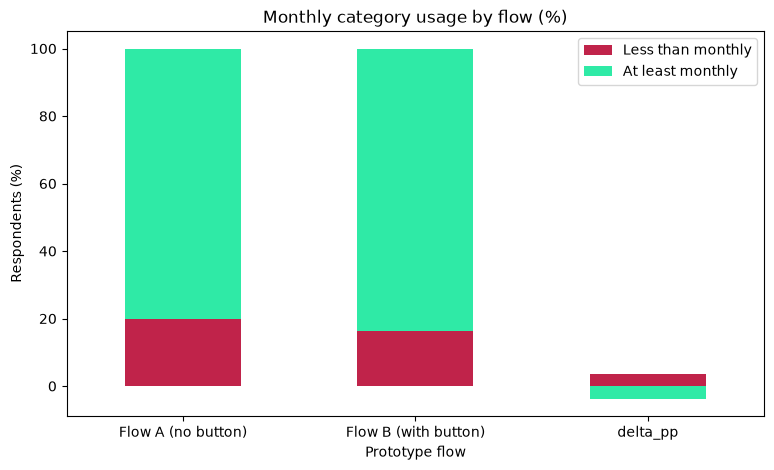

In [18]:
#visualise monthly category usage within each flow 
monthly_users_ax = monthly_users_pct_by_flow.T.plot (kind = 'bar', stacked = True, figsize = (9,5), color = ["#C0234A","#2FEAA6"])

monthly_users_ax.set_title('Monthly category usage by flow (%)')
monthly_users_ax.set_xlabel('Prototype flow')
monthly_users_ax.tick_params(axis='x', labelrotation=0)
monthly_users_ax.set_ylabel('Respondents (%)')
monthly_users_ax.legend (loc = 'upper right')

plt.show()

The share of monthly category users differs slightly between Flow A and Flow B. I will use a Pearson chi-square test to check whether this difference is statistically significant (α = 0.05).

- H0: Monthly category usage and flow assignment are independent; the underlying proportion of monthly users is the same across flows.
- H1: Monthly category usage and flow assignment are associated; the underlying proportion of monthly users differs across flows.

In [19]:
#run chi-2 statistical test
monthly_users_expected, _ , monthly_users_stats = pg.chi2_independence (data = df, x = 'monthly_users', y = 'Flow' )

monthly_users_chi2_results = monthly_users_stats.loc[monthly_users_stats['test'].eq('pearson')].round(2)


#print the results
print("Expected frequencies under H0")
display(monthly_users_expected.round(2))
print("\nResults")
display(monthly_users_chi2_results)


Expected frequencies under H0


Flow,Flow A (no button),Flow B (with button)
monthly_users,,
False,18.18,17.82
True,81.82,80.18



Results


,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.0,0.24,1.0,0.63,0.03,0.08


Monthly category users account for 83.7% of respondents in Flow B and 80.0% in Flow A, an observed difference of 3.7 percentage points.

**This difference is not statistically significant (p = 0.63), so H0 is not rejected at α = 0.05. Cramér’s V = 0.03 suggests a weak link between monthly category usage and flow assignment in this sample.**

However, this difference in composition could still matter if regular and non-regular category users differ in how often they notice discounts.

### 7. Discount Motivated Users
Compare the proportion of respondents motivated by discounts

In [20]:
## define the target questions and inspect values, including missing responses
DISCOUNT_MOTIVATION = [c for c in df.columns if 'discount' in c.lower() and 'motivate' in c.lower()][0]

discount_motivated_counts = df[DISCOUNT_MOTIVATION].value_counts(dropna=False)

print(f"Overall discount motivated respondents breakdown:\n{discount_motivated_counts.to_string()}")


Overall discount motivated respondents breakdown:
Q31. Based on your previous experience, what usually motivates you to make a purchase or shift your choice in favor of a particular option? Discount on the product or service
NaN                                   122
Discount on the product or service     76


In [21]:
#flag those motivated by discounts and build a col for them
df['is_motivated_by_discounts'] = df[DISCOUNT_MOTIVATION].notna()

#count discount motivated respondents by flow
motivated_by_discounts_counts_by_flow = pd.crosstab (df['is_motivated_by_discounts'], df['Flow'])


#calculate proportions within each flow
motivated_by_discounts_pct_by_flow = (motivated_by_discounts_counts_by_flow.div(motivated_by_discounts_counts_by_flow.sum (axis = 0), axis = 'columns')
                             .mul(100)
                             .round(2))
motivated_by_discounts_pct_by_flow['delta_pp'] = motivated_by_discounts_pct_by_flow['Flow A (no button)'] - motivated_by_discounts_pct_by_flow['Flow B (with button)']

#print results
print("Motivated by discounts by flow (counts)")
display(motivated_by_discounts_counts_by_flow)
print("\nMotivated by discounts by flow (%)")
display(motivated_by_discounts_pct_by_flow)


Motivated by discounts by flow (counts)


Flow,Flow A (no button),Flow B (with button)
is_motivated_by_discounts,,
False,60,62
True,40,36



Motivated by discounts by flow (%)


Flow,Flow A (no button),Flow B (with button),delta_pp
is_motivated_by_discounts,,,
False,60.0,63.27,-3.27
True,40.0,36.73,3.27


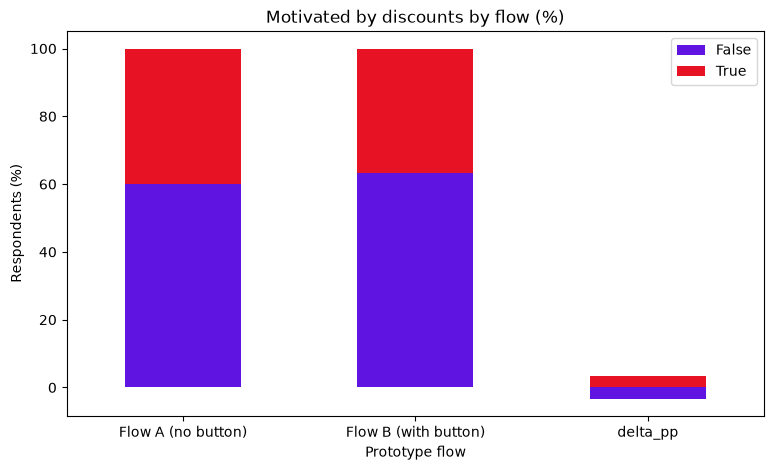

In [22]:
#visualize the distribution comparison
motivated_by_discounts_ax = (motivated_by_discounts_pct_by_flow.
                             T.plot (kind = 'bar', stacked = True, figsize = (9,5), color = ["#6014E2", "#E71223"]))
motivated_by_discounts_ax.set_title('Motivated by discounts by flow (%)')
motivated_by_discounts_ax.set_xlabel('Prototype flow')
motivated_by_discounts_ax.tick_params(axis='x', labelrotation=0)
motivated_by_discounts_ax.set_ylabel('Respondents (%)')
motivated_by_discounts_ax.legend (loc = 'upper right')

plt.show()

The share of respondents motivated by discounts differs slightly between Flow A and Flow B. I will use a Pearson chi-square test to check whether this difference is statistically significant (α = 0.05).

- H0: Discount motivation and flow assignment are independent: the underlying proportion of discount-motivated respondents is the same across flows.
- H1: Discount motivation and flow assignment are associated: the underlying proportion of discount-motivated respondents differs across flows.

In [23]:
#run chi2 test
motivated_by_discounts_expected, _ , motivated_by_discounts_stats = pg.chi2_independence (data = df, x ='is_motivated_by_discounts', y = 'Flow' )

motivated_by_discounts_stats = motivated_by_discounts_stats.loc [motivated_by_discounts_stats['test'].eq('pearson')].round(2)

#print the results
print("Expected frequencies under H0")
display(motivated_by_discounts_expected.round(2))
print("\nResults")
display(motivated_by_discounts_stats)


Expected frequencies under H0


Flow,Flow A (no button),Flow B (with button)
is_motivated_by_discounts,,
False,61.62,60.38
True,38.38,37.62



Results


,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.0,0.11,1.0,0.74,0.02,0.06


Discount-motivated respondents account for 40.00% of Flow A and 36.73% of Flow B, an observed difference of 3.27 percentage points.  

**This difference is not statistically significant (p = 0.74), so H0 is not rejected at α = 0.05. Cramér’s V = 0.02 suggests a weak link between discount motivation and flow assignment in this sample.**

However, this difference could still matter if discount-motivated respondents are more likely to notice discounts.

### 8. Summary

Flow A and Flow B have nearly equal sample sizes and closely matched prototype completion rates. 
Monthly category usage and the discount-related segment also show relatively small differences between flows.

The clearest observed differences are in gender and age composition: Flow B includes a higher proportion of female respondents and respondents aged 18–34, while Flow A includes a higher proportion aged 55–65.

None of the chi-square tests detected a statistically significant association with flow assignment at α = 0.05. However, this does not establish equivalent group composition.

The analysis will proceed with all 198 respondents without weighting the data. Gender and age composition will receive particular attention when interpreting differences in discount noticeability.

**Decision on Weighting**

The primary comparison will use unweighted data. Sample sizes and prototype completion rates are closely matched across flows, while some differences in gender and age composition remain.

A sensitivity analysis accounting for gender and age will assess whether these differences materially change the comparison of discount noticeability. Weighting is not introduced solely on the basis of baseline significance tests.